# Constitution du corpus France Travail
### Collecte des offres d’emploi Data / Intelligence artificielle

**TER — Analyse des compétences du marché de l’emploi**  
**Responsable de la collecte : Amina** · **Collecte : 31 octobre 2026**

---

Ce travail constitue le volet **acquisition des données** du projet. Il vise à produire un corpus d’offres issues de France Travail, traçable et exploitable par les étapes de préparation du dataset puis d’analyse des compétences avec ESCO.

Le présent notebook documente le processus réellement implémenté dans le dépôt, examine le corpus public et reproduit ses principaux contrôles. Il conserve les données sources et ne réalise aucune nouvelle collecte.

> **Résultat central : 664 occurrences collectées, regroupées en 615 offres uniques.**


## 1. Objectif scientifique et responsabilité

Les annonces d’emploi décrivent les profils, formations et compétences attendus par les employeurs. Leur collecte constitue le point de départ de l’étude des besoins du marché pour les métiers Data / IA.

La mission de collecte couvre l’accès à la source, la formulation des recherches, la pagination, la consolidation des résultats, le dédoublonnage par identifiant et la transmission d’une version publique du corpus.

| Dans le périmètre de cette partie | Étapes suivantes du groupe |
|---|---|
| Acquisition et traçabilité des offres | Nettoyage et structuration du dataset |
| Conservation des descriptions et champs de l’API | Validation métier et décisions d’exclusion |
| Contrôles du corpus collecté | MCD/MOD, extraction des compétences et rapprochement ESCO |

Cette distinction permet de conserver une source de référence tout en laissant les décisions de préparation des données à la partie correspondante.


## 2. Périmètre de recherche

| Dimension | Choix retenu |
|---|---|
| Métiers recherchés | Data Analyst, Data Scientist, Data Engineer, Machine Learning Engineer, Développeur IA |
| Contrats ciblés | CDI, CDD et alternance |
| Fenêtre demandée | 365 jours avant le lancement de la collecte |
| Source | API Offres d’emploi v2 de France Travail |
| Unité du corpus final | Une offre identifiée par son `id` France Travail |
| Population accessible | Offres actives accessibles au moment de la collecte |

Les métiers sont recherchés par **mots-clés**, et non par une liste restrictive de codes ROME. Un intitulé recherché peut donc ramener plusieurs métiers proches ou des offres hors du périmètre final. Le script ne fixe pas de restriction géographique explicite : la décision sur les offres à l’étranger appartient au cadrage collectif.


## 3. Source et chaîne d’acquisition

Le code de référence est `src/france_travail/collect_offres.py`.

| Étape | Traitement implémenté |
|---|---|
| Authentification | OAuth2, flux `client_credentials`, variables `CLIENT_ID` et `CLIENT_SECRET` lues dans un `.env` local |
| Autorisation | Scopes `api_offresdemploiv2 o2dsoffre` |
| Recherche | Endpoint `/partenaire/offresdemploi/v2/offres/search`, paramètre `motsCles` |
| Dates | Paramètres `minCreationDate` et `maxCreationDate` |
| CDI / CDD | Requêtes avec `typeContrat`, puis exclusion des offres marquées en alternance de ces deux catégories |
| Alternance | Recherche sans filtre de contrat, puis conservation de `alternance = True` |
| Pagination | Paramètre `range`, plages successives de 150 résultats |
| Consolidation | Regroupement des recherches, déduplication sur `id`, création d’un résumé et des métadonnées |
| Publication | Suppression récursive des clés `contact` et `agence` dans une copie publique |

**Précisions sur le fonctionnement du script.** Les réponses HTTP 200 et 206 sont traitées. Une page contenant moins de 150 offres termine une recherche. Le script s’arrête également sur une erreur HTTP ou lorsque sa limite de pagination est atteinte ; il n’implémente pas de reprise automatique. Le corpus sauvegardé ne constitue donc pas une preuve d’exhaustivité des recherches.

La déduplication utilise un dictionnaire indexé par `id` : la dernière occurrence rencontrée remplace les précédentes. Le collecteur ne sélectionne pas explicitement la version ayant la date d’actualisation la plus récente.


## 4. Corpus public et organisation des fichiers

Le fichier de référence est **`data/raw/offres_france_travail_public_2026-10-31_13-43.json`**.

La publication retire les champs structurés `contact` et `agence` au moyen de `nettoyer_json_public.py`. Elle ne constitue ni une anonymisation exhaustive des descriptions en texte libre ni le nettoyage métier du dataset.

| Fichier du dépôt | Fonction |
|---|---|
| `src/france_travail/collect_offres.py` | Acquisition et consolidation des offres |
| `src/france_travail/nettoyer_json_public.py` | Création de la copie publique depuis le brut local |
| `src/france_travail/verifier_collecte.py` | Contrôle de présence des champs du corpus public |
| `reports/weekly/collecte_france_travail.md` | Documentation de la collecte |
| `src/france_travail/collecte_france_travail.ipynb` | Présentation et contrôles détaillés du corpus |


In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import json
import re

NOM_JSON = "offres_france_travail_public_2026-10-31_13-43.json"
candidats = [Path.cwd(), *Path.cwd().parents]
RACINE = next((p for p in candidats if (p / "data" / "raw" / NOM_JSON).is_file()), None)
if RACINE is None:
    raise FileNotFoundError("Ouvrir le notebook depuis la racine du dépôt ou src/france_travail/.")
FICHIER = RACINE / "data" / "raw" / NOM_JSON
with FICHIER.open(encoding="utf-8") as f:
    corpus = json.load(f)
assert {"metadata", "resume", "resultats_par_metier", "offres_uniques"} <= corpus.keys()
metadata = corpus["metadata"]
offres = corpus["offres_uniques"]
assert offres, "Le corpus est vide."
print("Corpus :", FICHIER.relative_to(RACINE).as_posix())
print("Source :", metadata["source"], "—", metadata["api"])
print("Date de collecte :", metadata["date_collecte"])
print("Nombre d’offres :", len(offres))


Corpus : data/raw/offres_france_travail_public_2026-10-31_13-43.json
Source : France Travail — API Offres d'emploi v2
Date de collecte : 2026-10-31T12:43:25.872273+00:00
Nombre d’offres : 615


In [2]:
from html import escape
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (10, 4.8), 'figure.dpi': 120,
    'font.size': 11, 'axes.titlesize': 14, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': '#334155', 'text.color': '#172b4d',
    'axes.edgecolor': '#cbd5e1', 'savefig.facecolor': 'white'
})
COULEURS = ['#245b83', '#399c9d', '#e5a347']

class Tableau:
    def __init__(self, entetes, lignes):
        self.entetes = entetes
        self.lignes = list(lignes)
    def _repr_html_(self):
        th = ''.join('<th style="padding:10px;text-align:left;background:#183b56;color:white">'+escape(str(v))+'</th>' for v in self.entetes)
        rows = []
        for i, ligne in enumerate(self.lignes):
            fond = '#f1f5f9' if i % 2 == 0 else '#ffffff'
            rows.append('<tr>'+''.join('<td style="padding:9px 12px;border-bottom:1px solid #e2e8f0;background:'+fond+'">'+escape(str(v))+'</td>' for v in ligne)+'</tr>')
        return '<table style="border-collapse:collapse;font-family:Arial,sans-serif;font-size:14px"><thead><tr>'+th+'</tr></thead><tbody>'+''.join(rows)+'</tbody></table>'
    def __repr__(self):
        return '\n'.join([' | '.join(map(str,self.entetes))]+[' | '.join(map(str,r)) for r in self.lignes])


### 4.1 Structure du JSON et traçabilité

Les quatre blocs sont complémentaires : `metadata` décrit la collecte ; `resume` donne les effectifs des recherches ; `resultats_par_metier` conserve leurs résultats ; `offres_uniques` contient le corpus global dédoublonné.

Les métadonnées enregistrent la date minimale demandée et la date de collecte. La valeur exacte de `maxCreationDate` n’est pas enregistrée : la date de collecte sera utilisée comme borne supérieure de contrôle.


In [3]:
Tableau(['Indicateur', 'Valeur enregistrée'], [
    ['Source', metadata['source']], ['API', metadata['api']],
    ['Date de collecte (UTC)', metadata['date_collecte']],
    ['Date minimale demandée', metadata['date_minimum']],
    ['Occurrences déclarées', metadata['nombre_occurrences_avant_dedoublonnage']],
    ['Offres uniques déclarées', metadata['nombre_offres_uniques']]
])


Indicateur,Valeur enregistrée
Source,France Travail
API,API Offres d'emploi v2
Date de collecte (UTC),2026-10-31T12:43:25.872273+00:00
Date minimale demandée,2025-10-31T12:43:01Z
Occurrences déclarées,664
Offres uniques déclarées,615


## 5. Résultats des recherches par métier

Les effectifs ci-dessous sont calculés à partir des listes réellement présentes dans le JSON, puis comparés au bloc `resume`. Ils correspondent à des **résultats de recherche**, et non à cinq catégories professionnelles exclusives.


In [4]:
metiers = list(corpus['resultats_par_metier'])
categories_contrats = ['CDI', 'CDD', 'Alternance']
lignes_recherches = []
for metier in metiers:
    categories = corpus['resultats_par_metier'][metier]
    effectifs = [len(categories[c]) for c in categories_contrats]
    for c, n in zip(categories_contrats, effectifs):
        assert n == corpus['resume'][metier][c], 'Incohérence du résumé.'
    lignes_recherches.append([metier, *effectifs, sum(effectifs)])
occurrences = sum(l[-1] for l in lignes_recherches)
assert occurrences == metadata['nombre_occurrences_avant_dedoublonnage']
Tableau(['Métier recherché', 'CDI', 'CDD', 'Alternance', 'Total'], lignes_recherches + [['TOTAL', *[sum(l[i] for l in lignes_recherches) for i in range(1, 5)]]])


Métier recherché,CDI,CDD,Alternance,Total
Data Analyst,118,11,12,141
Data Scientist,59,5,1,65
Data Engineer,316,19,7,342
Machine Learning Engineer,29,1,1,31
Développeur IA,65,5,15,85
TOTAL,587,41,36,664


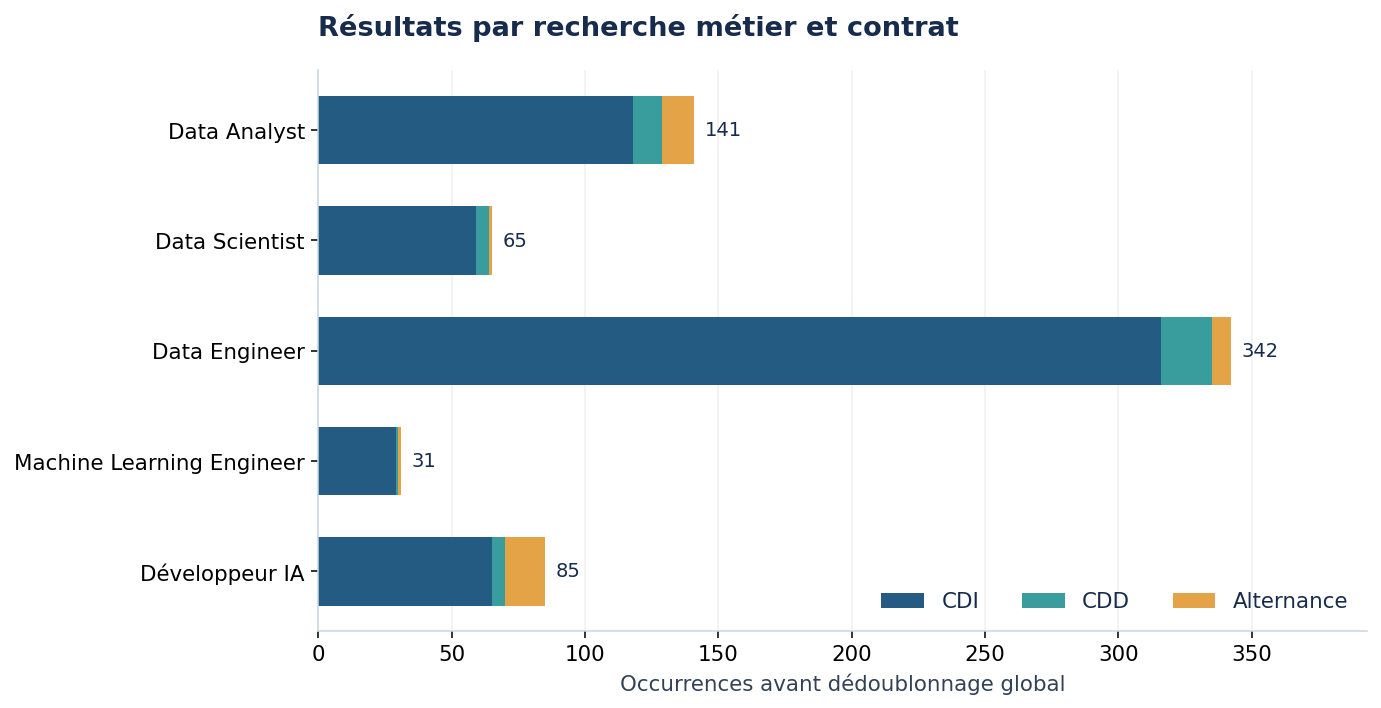

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
gauche = [0] * len(metiers)
for contrat, couleur in zip(categories_contrats, COULEURS):
    valeurs = [len(corpus['resultats_par_metier'][m][contrat]) for m in metiers]
    ax.barh(metiers, valeurs, left=gauche, label=contrat, color=couleur, height=0.62)
    gauche = [a+b for a,b in zip(gauche,valeurs)]
for i, total in enumerate(gauche):
    ax.text(total+4, i, str(total), va='center', fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, max(gauche)*1.15)
ax.set_title('Résultats par recherche métier et contrat', loc='left', pad=18)
ax.set_xlabel('Occurrences avant dédoublonnage global')
ax.legend(frameon=False, ncol=3, loc='lower right')
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.18)
fig.tight_layout()
plt.show()


**Lecture.** La recherche « Data Engineer » fournit le volume le plus important. Ces effectifs dépendent des mots-clés utilisés et des résultats accessibles dans l’API ; ils ne mesurent pas à eux seuls la part de chaque métier sur le marché de l’emploi.

## 6. Consolidation et dédoublonnage

La même annonce peut être trouvée dans plusieurs recherches. L’identifiant France Travail permet de réunir ces occurrences en un seul enregistrement.

Le contrôle reproduit en mémoire la consolidation du collecteur et compare les enregistrements obtenus à `offres_uniques`.


In [6]:
identifiants = [o.get('id') for o in offres]
assert all(identifiants), 'Identifiant manquant.'
assert len(set(identifiants)) == len(offres), 'Doublon dans le corpus unique.'
reconstituees = {}
for categories in corpus['resultats_par_metier'].values():
    for liste in categories.values():
        for offre in liste:
            reconstituees[offre['id']] = offre
assert list(reconstituees.values()) == offres, 'Différence avec la consolidation du collecteur.'
assert len(offres) == metadata['nombre_offres_uniques']
recouvrements = occurrences - len(offres)
Tableau(['Indicateur', 'Résultat'], [
    ['Occurrences de recherche', occurrences], ['Identifiants distincts', len(set(identifiants))],
    ['Occurrences supplémentaires retirées', recouvrements],
    ['Part des occurrences supplémentaires', f'{100*recouvrements/occurrences:.1f} %'],
    ['Reconstitution du corpus unique', 'Conforme']
])


Indicateur,Résultat
Occurrences de recherche,664
Identifiants distincts,615
Occurrences supplémentaires retirées,49
Part des occurrences supplémentaires,7.4 %
Reconstitution du corpus unique,Conforme


Les **49 occurrences supplémentaires** retirées ne signifient pas que 49 offres distinctes sont supprimées : plusieurs occurrences peuvent concerner une même annonce. Le dédoublonnage par `id` ne repère pas les annonces semblables publiées sous des identifiants différents.

## 7. Répartition des contrats après dédoublonnage

L’API représente l’alternance par un booléen, en complément du type de contrat. Pour obtenir une répartition exclusive, la catégorie alternance est prioritaire sur CDI et CDD.


In [7]:
def categorie_contrat(offre):
    return 'Alternance' if offre.get('alternance') is True else offre.get('typeContrat', 'Non renseigné')
contrats = Counter(categorie_contrat(o) for o in offres)
assert sum(contrats.values()) == len(offres)
assert set(contrats) <= set(categories_contrats)
Tableau(['Catégorie exclusive', 'Offres uniques', 'Part'], [
    [c, contrats[c], f'{100*contrats[c]/len(offres):.1f} %'] for c in categories_contrats
])


Catégorie exclusive,Offres uniques,Part
CDI,542,88.1 %
CDD,39,6.3 %
Alternance,34,5.5 %


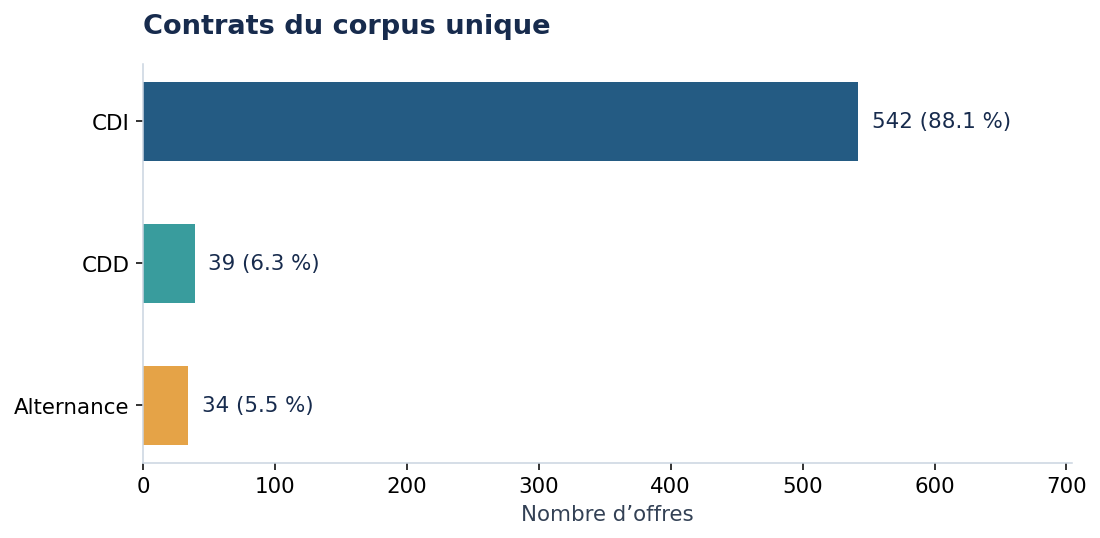

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
valeurs = [contrats[c] for c in categories_contrats]
barres = ax.barh(categories_contrats, valeurs, color=COULEURS, height=0.55)
ax.bar_label(barres, labels=[f'{n} ({100*n/len(offres):.1f} %)' for n in valeurs], padding=7)
ax.invert_yaxis()
ax.set_xlim(0, max(valeurs)*1.30)
ax.set_title('Contrats du corpus unique', loc='left', pad=16)
ax.set_xlabel('Nombre d’offres')
fig.tight_layout()
plt.show()


Cette répartition décrit le corpus de collecte avant validation métier. Certaines annonces classées CDI/CDD par la source correspondent notamment à des stages dans leur intitulé.

## 8. Couverture temporelle des offres actives

L’objectif est de récupérer les offres actives accessibles avec un filtre de création d’un an. Il ne s’agit pas d’un historique exhaustif des annonces publiées puis clôturées pendant cette période. L’état actif lors de la collecte ne garantit pas que ces offres restent actives aujourd’hui.


In [9]:
def date_api(valeur):
    return datetime.fromisoformat(valeur.replace('Z', '+00:00'))
debut = date_api(metadata['date_minimum'])
reference = date_api(metadata['date_collecte'])
dates_creation = [date_api(o['dateCreation']) for o in offres]
hors_fenetre = sum(not debut <= d <= reference for d in dates_creation)
assert hors_fenetre == 0
Tableau(['Repère temporel', 'Date'], [
    ['Début du filtre demandé', debut.date()], ['Collecte', reference.date()],
    ['Première création observée', min(dates_creation).date()],
    ['Dernière création observée', max(dates_creation).date()],
    ['Offres hors fenêtre de contrôle', hors_fenetre]
])


Repère temporel,Date
Début du filtre demandé,2025-10-31
Collecte,2026-10-31
Première création observée,2026-05-07
Dernière création observée,2026-10-31
Offres hors fenêtre de contrôle,0


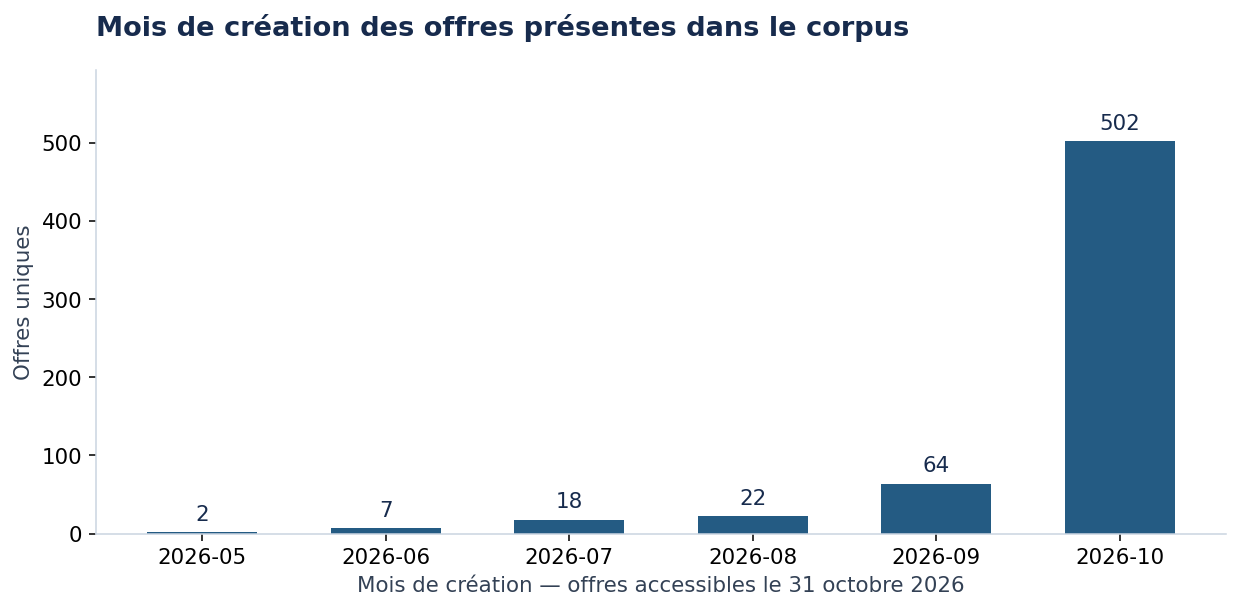

In [10]:
mois = Counter(d.strftime('%Y-%m') for d in dates_creation)
ordre_mois = sorted(mois)
fig, ax = plt.subplots(figsize=(9, 4.5))
barres = ax.bar(ordre_mois, [mois[m] for m in ordre_mois], color='#245b83', width=0.6)
ax.bar_label(barres, padding=4)
ax.set_ylim(0, max(mois.values())*1.18)
ax.set_title('Mois de création des offres présentes dans le corpus', loc='left', pad=18)
ax.set_ylabel('Offres uniques')
ax.set_xlabel('Mois de création — offres accessibles le 31 octobre 2026')
fig.tight_layout()
plt.show()


La distribution temporelle est conditionnée par la disponibilité des annonces lors de la collecte. Elle ne permet pas de conclure à une évolution mensuelle du volume total d’offres publiées sur le marché.

## 9. Complétude des informations collectées

Le contrôle distingue un champ présent d’une valeur exploitable. Les chaînes vides, listes vides, dictionnaires vides et valeurs nulles sont considérés comme non renseignés. Le booléen `False` reste une information valide.

Pour les objets imbriqués, la présence de `entreprise` ou de `lieuTravail` ne garantit pas la présence de `entreprise.nom` ou de `lieuTravail.commune`.


In [11]:
def renseigne(v):
    if v is None: return False
    if isinstance(v, str): return bool(v.strip())
    if isinstance(v, (list, dict)): return bool(v)
    return True
champs = ['id','intitule','description','dateCreation','dateActualisation','romeCode','romeLibelle',
          'entreprise','lieuTravail','typeContrat','experienceLibelle','formations','competences','alternance']
completude = {c:sum(renseigne(o.get(c)) for o in offres) for c in champs}
for parent,enfant in [('entreprise','nom'),('lieuTravail','commune')]:
    completude[f'{parent}.{enfant}'] = sum(renseigne((o.get(parent) or {}).get(enfant)) for o in offres)
for c in ['id','intitule','description','dateCreation','typeContrat']:
    assert completude[c] == len(offres), f'Champ essentiel incomplet : {c}'
Tableau(['Champ', 'Renseigné', 'Non renseigné', 'Complétude'], [
    [c,n,len(offres)-n,f'{100*n/len(offres):.1f} %'] for c,n in completude.items()
])


Champ,Renseigné,Non renseigné,Complétude
id,615,0,100.0 %
intitule,615,0,100.0 %
description,615,0,100.0 %
dateCreation,615,0,100.0 %
dateActualisation,615,0,100.0 %
romeCode,615,0,100.0 %
romeLibelle,615,0,100.0 %
entreprise,410,205,66.7 %
lieuTravail,615,0,100.0 %
typeContrat,615,0,100.0 %


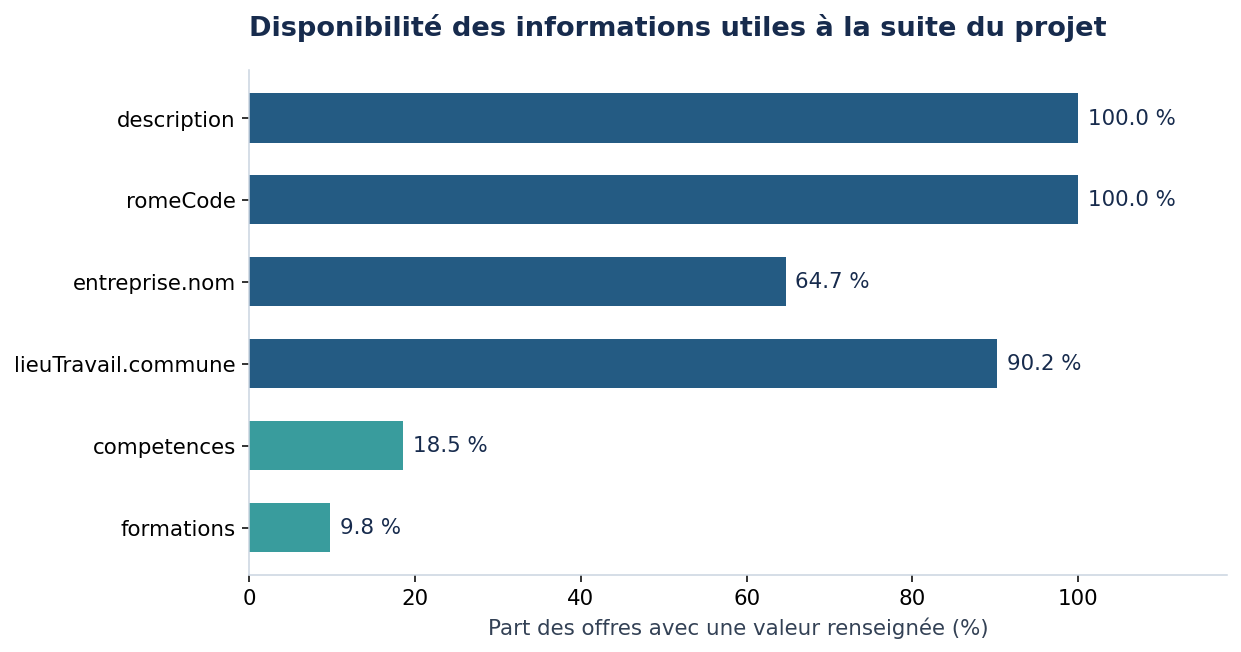

In [12]:
selection = ['description','romeCode','entreprise.nom','lieuTravail.commune','competences','formations']
fig, ax = plt.subplots(figsize=(9, 4.8))
parts = [100*completude[c]/len(offres) for c in selection]
barres = ax.barh(selection, parts, color=['#245b83']*4+['#399c9d']*2, height=0.6)
ax.bar_label(barres, labels=[f'{v:.1f} %' for v in parts], padding=5)
ax.invert_yaxis()
ax.set_xlim(0, 118)
ax.set_title('Disponibilité des informations utiles à la suite du projet', loc='left', pad=18)
ax.set_xlabel('Part des offres avec une valeur renseignée (%)')
fig.tight_layout()
plt.show()


**Interprétation.** Les descriptions sont disponibles pour les 615 offres. Les formations structurées sont renseignées pour **60 offres (9,8 %)** et les compétences pour **114 offres (18,5 %)**. L’absence de ces champs ne signifie pas qu’aucune formation ou compétence n’est demandée. Le texte libre constitue donc une source importante pour les étapes ultérieures.

## 10. Contrôle des champs retirés avant publication

Le contrôle parcourt toutes les sections du JSON, y compris les résultats par métier. Il vérifie l’absence des clés supprimées par le script de publication ; il ne recherche pas les éventuelles données personnelles dans le texte libre.


In [13]:
def compter_champs_retires(obj):
    if isinstance(obj, dict):
        return sum(int(k in {'contact','agence'}) + compter_champs_retires(v) for k,v in obj.items())
    if isinstance(obj, list):
        return sum(compter_champs_retires(v) for v in obj)
    return 0
champs_residuels = compter_champs_retires(corpus)
assert champs_residuels == 0
Tableau(['Contrôle', 'Résultat'], [
    ['Fichier sélectionné', FICHIER.name],
    ['Clés contact/agence présentes dans le JSON', champs_residuels],
    ['Offres uniques conservées', len(offres)],
    ['Modification du corpus par ce notebook', 'Aucune']
])


Contrôle,Résultat
Fichier sélectionné,offres_france_travail_public_2026-10-31_13-43.json
Clés contact/agence présentes dans le JSON,0
Offres uniques conservées,615
Modification du corpus par ce notebook,Aucune


## 11. Limites métier et points transmis au nettoyage

Le filtrage de la collecte délimite une population de recherche ; il ne remplace pas la validation des annonces. Le repérage des stages ci-dessous utilise le motif `stage` comme mot entier ou `stagiaire` dans le titre. Il s’agit d’un signal à examiner, sans suppression dans le corpus.


In [14]:
stages_signales = sum(bool(re.search(r'\bstage\b|stagiaire', o.get('intitule',''), re.IGNORECASE)) for o in offres)
Tableau(['Indicateur', 'Effectif'], [
    ['Corpus de collecte conservé', len(offres)],
    ['Titres signalés par le motif stage/stagiaire', stages_signales]
])


Indicateur,Effectif
Corpus de collecte conservé,615
Titres signalés par le motif stage/stagiaire,18


| Limite | Conséquence pour l’interprétation ou la préparation |
|---|---|
| Recherche par mots-clés | Présence possible d’offres éloignées des métiers ciblés |
| Stages classés en CDI/CDD par la source | Contrôle du titre et décision dans le nettoyage |
| Absence de filtre géographique explicite | Décision collective sur les offres hors de France |
| Recouvrements entre recherches | Les totaux par métier ne sont pas additifs après déduplication |
| Déduplication uniquement sur `id` | Des annonces proches avec des identifiants différents peuvent subsister |
| Dernière occurrence conservée | Pas de sélection explicite de la version la plus récente |
| Champs structurés peu complets | Exploitation complémentaire des descriptions |
| Offres actives à une date donnée | Aucune exhaustivité historique sur douze mois |
| Arrêt sur erreur ou limite de pagination | Complétude des réponses historiques non démontrée par le seul JSON |

Les **18 titres signalés comme stages** restent dans le corpus collecté. Le choix de les retirer relève de la préparation du dataset. Les 615 offres sont donc l’effectif de collecte, et non une promesse sur l’effectif final après nettoyage.

## 12. Transmission et articulation avec les autres parties

La partie nettoyage doit lire `data/raw/offres_france_travail_public_2026-10-31_13-43.json` et utiliser :

- **`offres_uniques`** pour les annonces dédoublonnées ;
- **`metadata.date_collecte`** pour la date de collecte ;
- **`metadata.source` et `metadata.api`** pour la provenance.

Le fichier public conserve les descriptions et les champs nécessaires à la conversion vers le dictionnaire de données du groupe. Les suppressions et transformations métier doivent être tracées dans les sorties du nettoyage, en préservant le corpus collecté.

## 13. Bilan

La partie collecte fournit un corpus public de **615 offres uniques**, issu de **664 occurrences** obtenues lors de recherches Data / IA sur les contrats retenus. Les identifiants, le résumé, les catégories de contrats, la fenêtre temporelle et l’absence des champs structurés retirés ont été contrôlés sur les données publiées.

Ce corpus constitue l’entrée de la préparation du dataset. Sa richesse principale réside dans les descriptions complètes ; ses limites concernent la disponibilité des offres actives, la précision des mots-clés et la faible complétude de certains champs structurés.

---
**Références du projet :** [dépôt GitHub](https://github.com/nafiamedreda/TER-Analyse-Competences-Marche-Emploi), [branche de collecte](https://github.com/nafiamedreda/TER-Analyse-Competences-Marche-Emploi/tree/amina-france-travail), [PR de collecte nº 3](https://github.com/nafiamedreda/TER-Analyse-Competences-Marche-Emploi/pull/3). Les constats ci-dessus sont calculés à partir du corpus public du 31 octobre 2026 et du code de collecte versionné.
